<a href="https://colab.research.google.com/github/Samar97adel/Machine-learning/blob/main/scatter_kmean_dbscan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [ ]:
#create simple dataset
x,y=make_blobs(
    n_samples=150,
    n_features=2,
    centers=3,
    cluster_std=0.7,
    shuffle=True,
    random_state=42
)

In [ ]:
#create and train kmean
kmeans=KMeans(n_clusters=3,
             init='random',
             n_init=10,
             max_iter=300,
             random_state=42)
kmeans.fit(x)

KMeans(init='random', n_clusters=3, n_init=10, random_state=42)

In [ ]:
labels=kmeans.labels_
centroids=kmeans.cluster_centers_
print('Cluster cetrer')
print(centroids)

Cluster cetrer
[[ 4.60081738  2.09215199]
 [-2.64378525  8.93630094]
 [-6.79168528 -6.88664699]]


In [ ]:
silhouette_score=silhouette_score(x,labels)
inertia=kmeans.inertia_

In [ ]:
scores=[]
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,
             init='random',
             n_init=10,
             max_iter=300,
             random_state=42
    )
    labels=kmeans.fit_predict(x)
    score=silhouette_score(x,labels)
    scores.append(score)

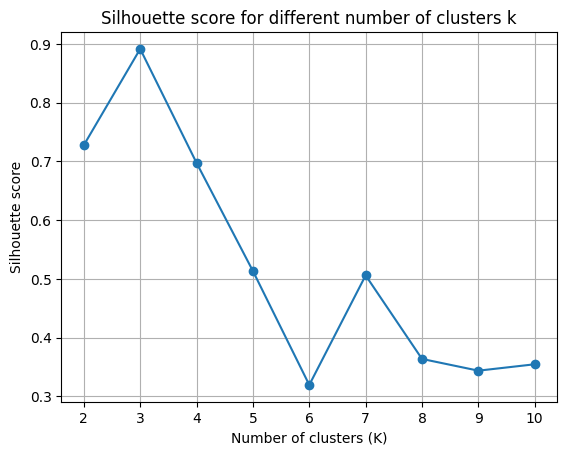

In [ ]:
plt.plot(range(2,11),scores,marker='o')
plt.title('Silhouette score for different number of clusters k')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette score')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN

In [ ]:
dbscan=DBSCAN(
    eps=0.8,
    min_samples=5,
    metric='euclidean'
)

In [ ]:
labels=dbscan.fit_predict(x)

In [ ]:
n_clusters=len(set(labels))-(1 if -1 in labels else 0)
n_noise=list(labels).count(-1)

In [ ]:
print('Number of clusters:',n_clusters)
print('Number of noise points:',n_noise)

Number of clusters: 3
Number of noise points: 3


In [ ]:
valid_mask= labels !=0
valid_labels=[valid_mask]

In [62]:
# Filter out noise points (where label is -1) to calculate silhouette score
valid_mask = labels != -1
filtered_x = x[valid_mask]
filtered_labels = labels[valid_mask]

# Silhouette score requires at least 2 unique clusters to be defined
unique_clusters = len(set(filtered_labels))

if unique_clusters >= 2:
    # Using the scikit-learn silhouette_score imported earlier
    # Note: silhouette_score was overwritten in cell xiBSbXw5DT_L as a float variable,
    # so we import it locally here to ensure we use the function.
    from sklearn.metrics import silhouette_score as sk_silhouette_score
    silhouette = sk_silhouette_score(filtered_x, filtered_labels)
    print('Silhouette score (excluding noise):', round(silhouette, 3))
else:
    print("Silhouette score: Not available (less than 2 clusters found)")

Silhouette score (excluding noise): 0.895


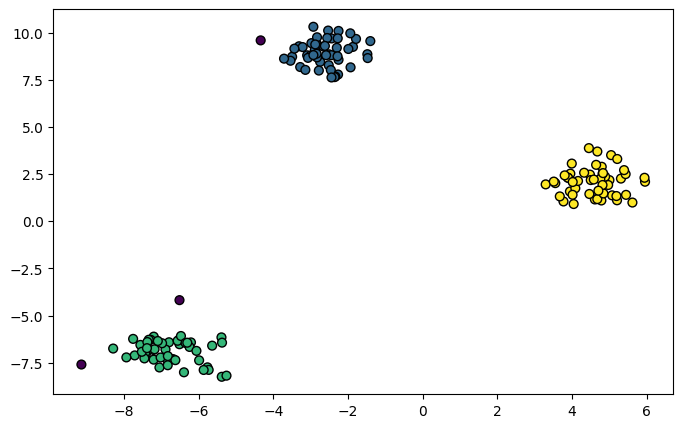

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(
    x[:,0],
    x[:,1],
    c=labels,
    cmap='viridis',
    edgecolor='k',
    s=40
)

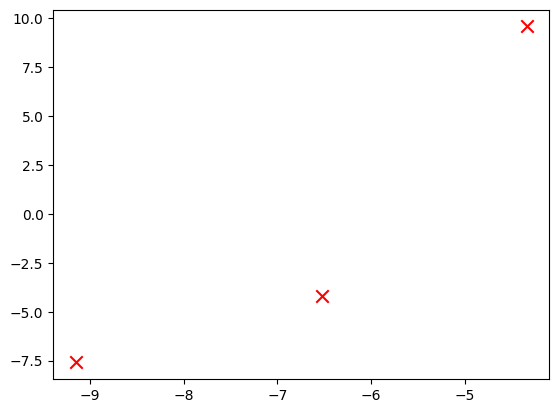

In [ ]:
plt.scatter(
    x[labels==-1,0],
    x[labels==-1,1],
    c='red',
    marker='x',
    s=80,
    label='Noise'
)